# Linear Regression — Best Config (h, alpha=0.0001)

Predicts a full day's 24 hourly GHI values from the previous day's 24 hours of weather data, using Ridge regression with the best alpha found by the sweep.

In [3]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from numpy.lib.stride_tricks import sliding_window_view
import joblib
import time

np.random.seed(42)

## 0. Run configuration

In [4]:
RUN_NAME = os.environ.get('RUN_NAME', 'h')
ALPHA = float(os.environ.get('ALPHA', '0.0001'))

print(f'Run "{RUN_NAME}": alpha={ALPHA}')

Run "h": alpha=0.0001


## 1. Load data and select features

In [5]:
# Load the dataset and add lag features

DATA_PATH = '../../../data/FYP_Cleaned_Dataset.csv'

df = pd.read_csv(DATA_PATH, parse_dates=['Datetime'])
df = df.sort_values(['State', 'Datetime']).reset_index(drop=True)


FEATURE_COLS = [
    'Latitude', 'Cloud_Coverage_Pct', 'Temp_Skin_C',
    'Relative_Humidity_Pct', 'Wind_Speed_10m_m_s',
    'Precipitable_Water_cm', 'Rainfall_mm_log', 'Is_Daylight',
    'Hour_sin', 'Hour_cos', 'Wind_Sine', 'Wind_Cosine',
    'GHI_lag_1h', 'GHI_lag_24h',
]
TARGET_COL = 'GHI_W_m2'

print(df.shape)
df.head()


(1314360, 20)


,Datetime,State,Latitude,Longitude,GHI_W_m2,Cloud_Coverage_Pct,Temp_Skin_C,Relative_Humidity_Pct,Wind_Speed_10m_m_s,Wind_Direction_10m_deg,Precipitable_Water_cm,Hour,Is_Daylight,Hour_sin,Hour_cos,Wind_Sine,Wind_Cosine,Rainfall_mm_log,GHI_lag_1h,GHI_lag_24h
0,2016-01-02 00:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.25,25.83,94.15,4.50,25.5,5.89,0,0,0.000000,1.000000,0.430511,0.902585,2.401525,0.0,0.0
1,2016-01-02 01:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.99,25.74,94.17,4.46,22.7,5.93,1,0,0.258819,0.965926,0.385906,0.922538,2.200552,0.0,0.0
2,2016-01-02 02:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.52,25.67,94.39,4.25,19.8,5.92,2,0,0.500000,0.866025,0.338738,0.940881,1.908060,0.0,0.0
3,2016-01-02 03:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.59,25.59,94.53,4.03,17.0,5.94,3,0,0.707107,0.707107,0.292372,0.956305,1.964311,0.0,0.0
4,2016-01-02 04:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.58,25.49,94.72,3.73,14.7,5.96,4,0,0.866025,0.500000,0.253758,0.967268,2.271094,0.0,0.0


## 2. Split data into train/val/test

In [6]:
TRAIN_FRAC = 0.7
VAL_FRAC = 0.1

def split_state(group):
    n = len(group)
    train_end = int(n * TRAIN_FRAC)
    val_end = int(n * (TRAIN_FRAC + VAL_FRAC))
    return group.iloc[:train_end], group.iloc[train_end:val_end], group.iloc[val_end:]

train_parts, val_parts, test_parts = [], [], []
for state, group in df.groupby('State', sort=False):
    tr, va, te = split_state(group)
    train_parts.append(tr); val_parts.append(va); test_parts.append(te)

train_df = pd.concat(train_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print('Train:', train_df.shape, train_df['Datetime'].min(), '-', train_df['Datetime'].max())
print('Val:  ', val_df.shape, val_df['Datetime'].min(), '-', val_df['Datetime'].max())
print('Test: ', test_df.shape, test_df['Datetime'].min(), '-', test_df['Datetime'].max())

Train: (920040, 20) 2016-01-02 00:00:00 - 2022-12-31 15:00:00
Val:   (131445, 20) 2022-12-31 16:00:00 - 2023-12-31 18:00:00
Test:  (262875, 20) 2023-12-31 19:00:00 - 2025-12-30 23:00:00


## 3. Scale features and target

In [7]:
x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(0, 1))

x_scaler.fit(train_df[FEATURE_COLS])
y_scaler.fit(train_df[[TARGET_COL]])

def scale(frame):
    frame = frame.copy()
    frame[FEATURE_COLS] = x_scaler.transform(frame[FEATURE_COLS])
    frame[TARGET_COL + '_scaled'] = y_scaler.transform(frame[[TARGET_COL]])
    return frame

train_scaled = scale(train_df)
val_scaled = scale(val_df)
test_scaled = scale(test_df)

## 4. Build input/output windows

In [8]:
WINDOW_SIZE = 24
OUTPUT_HORIZON = 24  # direct multi-step: predict the whole next day at once

def build_multistep_arrays(frame, stride=1):
    X_list, y_list = [], []
    for _, group in frame.groupby('State', sort=False):
        group = group.sort_values('Datetime')
        n = len(group)
        if n <= WINDOW_SIZE + OUTPUT_HORIZON:
            continue
        X = group[FEATURE_COLS].to_numpy(dtype='float32')
        y = group[TARGET_COL + '_scaled'].to_numpy(dtype='float32')

        # offset views so identical windowing on both arrays yields aligned
        # (D window) <-> (D+1 target window) pairs -- same trick as the
        # LSTM/Transformer notebooks' tf.data version
        X_for_windowing = X[: n - OUTPUT_HORIZON]
        y_for_windowing = y[WINDOW_SIZE:]

        # (n_windows, n_features, WINDOW_SIZE) -> (n_windows, WINDOW_SIZE, n_features) -> flatten
        Xw = sliding_window_view(X_for_windowing, WINDOW_SIZE, axis=0)[::stride]
        Xw = Xw.transpose(0, 2, 1).reshape(Xw.shape[0], -1)
        yw = sliding_window_view(y_for_windowing, OUTPUT_HORIZON, axis=0)[::stride]

        X_list.append(Xw)
        y_list.append(yw)

    return np.concatenate(X_list, axis=0), np.concatenate(y_list, axis=0)

X_train, y_train = build_multistep_arrays(train_scaled, stride=1)
X_val, y_val = build_multistep_arrays(val_scaled, stride=1)
X_test, y_test = build_multistep_arrays(test_scaled, stride=1)

print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_val:  ', X_val.shape, 'y_val:  ', y_val.shape)
print('X_test: ', X_test.shape, 'y_test: ', y_test.shape)

X_train: (919335, 336) y_train: (919335, 24)
X_val:   (130740, 336) y_val:   (130740, 24)
X_test:  (262170, 336) y_test:  (262170, 24)


## 5. Define the model

In [9]:
model = LinearRegression() if ALPHA == 0 else Ridge(alpha=ALPHA)
print(model)
print(model.get_params())


Ridge(alpha=0.0001)
{'alpha': 0.0001, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}


## 6. Train the model

In [10]:
train_start = time.time()
model.fit(X_train, y_train)
train_duration_sec = time.time() - train_start

print(f'Training time: {train_duration_sec:.2f} sec')

Training time: 13.51 sec


## 6b. Validation evaluation (the metric that picks the sweep winner)

In [11]:
val_pred_scaled = model.predict(X_val)  # (n, 24)

y_true_val = y_scaler.inverse_transform(y_val.reshape(-1, 1)).reshape(y_val.shape)
y_pred_val = y_scaler.inverse_transform(val_pred_scaled.reshape(-1, 1)).reshape(val_pred_scaled.shape)
y_pred_val = np.clip(y_pred_val, 0, None)

y_true_val_flat = y_true_val.flatten()
y_pred_val_flat = y_pred_val.flatten()

val_mae = mean_absolute_error(y_true_val_flat, y_pred_val_flat)
val_rmse = np.sqrt(mean_squared_error(y_true_val_flat, y_pred_val_flat))
val_r2 = r2_score(y_true_val_flat, y_pred_val_flat)
val_mbe = np.mean(y_pred_val_flat - y_true_val_flat)
val_nrmse = (val_rmse / np.mean(y_true_val_flat)) * 100

print(f'Validation (all origins, all horizons pooled) MAE: {val_mae:.4f}  RMSE: {val_rmse:.4f}  '
      f'R2: {val_r2:.4f}  MBE: {val_mbe:.4f}  nRMSE: {val_nrmse:.2f}%  (W/m², nRMSE in %)')
print('^ this is the number that should decide the sweep winner, not the test metrics below.')

Validation (all origins, all horizons pooled) MAE: 38.3342  RMSE: 70.9852  R2: 0.9329  MBE: 3.2215  nRMSE: 35.04%  (W/m², nRMSE in %)
^ this is the number that should decide the sweep winner, not the test metrics below.


## 7. Evaluate on test set

In [12]:
y_pred_scaled = model.predict(X_test)  # (n, 24)

y_true = y_scaler.inverse_transform(y_test.reshape(-1, 1)).reshape(y_test.shape)
y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(y_pred_scaled.shape)
y_pred = np.clip(y_pred, 0, None)

y_true_flat_test = y_true.flatten()
y_pred_flat_test = y_pred.flatten()

mae = mean_absolute_error(y_true_flat_test, y_pred_flat_test)
rmse = np.sqrt(mean_squared_error(y_true_flat_test, y_pred_flat_test))
r2 = r2_score(y_true_flat_test, y_pred_flat_test)
test_mbe = np.mean(y_pred_flat_test - y_true_flat_test)
test_nrmse = (rmse / np.mean(y_true_flat_test)) * 100
print(f'Test (all origins, all horizons pooled) MAE: {mae:.4f}  RMSE: {rmse:.4f}  R2: {r2:.4f}  '
      f'MBE: {test_mbe:.4f}  nRMSE: {test_nrmse:.2f}%  (W/m², nRMSE in %)')

test_horizon_rows = []
for h in range(OUTPUT_HORIZON):
    yt, yp = y_true[:, h], y_pred[:, h]
    test_horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
test_horizon_df = pd.DataFrame(test_horizon_rows)
test_horizon_df

Test (all origins, all horizons pooled) MAE: 38.8734  RMSE: 72.0799  R2: 0.9310  MBE: 2.7301  nRMSE: 35.50%  (W/m², nRMSE in %)


,horizon_h,mae,rmse,r2
0,1,28.103144,48.301811,0.969009
1,2,34.056755,58.919979,0.953886
2,3,37.244781,65.276276,0.943399
3,4,38.760704,68.865904,0.937003
4,5,39.363518,70.740351,0.933527
5,6,39.525524,71.705163,0.931701
6,7,39.543655,72.252656,0.930654
7,8,39.524345,72.674937,0.929839
8,9,39.505402,73.079202,0.929055
9,10,39.553833,73.455932,0.928325


In [13]:
# Compute a persistence baseline for comparison ("tomorrow looks like today")

baseline_true_parts, baseline_pred_parts = [], []
for _, group in test_df.groupby('State', sort=False):
    group = group.sort_values('Datetime')
    values = group[TARGET_COL].to_numpy()
    n = len(values)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue
    windows = sliding_window_view(values, WINDOW_SIZE + OUTPUT_HORIZON)
    baseline_pred_parts.append(windows[:, :WINDOW_SIZE])
    baseline_true_parts.append(windows[:, WINDOW_SIZE:])

baseline_true = np.concatenate(baseline_true_parts).flatten()
baseline_pred = np.concatenate(baseline_pred_parts).flatten()
baseline_mae = mean_absolute_error(baseline_true, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(baseline_true, baseline_pred))

print(f'Persistence (D+1 = D) baseline MAE: {baseline_mae:.4f}  RMSE: {baseline_rmse:.4f}')
print(f'Improvement over baseline: MAE {(baseline_mae-mae)/baseline_mae*100:.2f}%  RMSE {(baseline_rmse-rmse)/baseline_rmse*100:.2f}%')


Persistence (D+1 = D) baseline MAE: 43.7046  RMSE: 94.1648
Improvement over baseline: MAE 11.05%  RMSE 23.45%


## 8. Plot predicted vs actual, pooled across all 15 states (validation + test period)

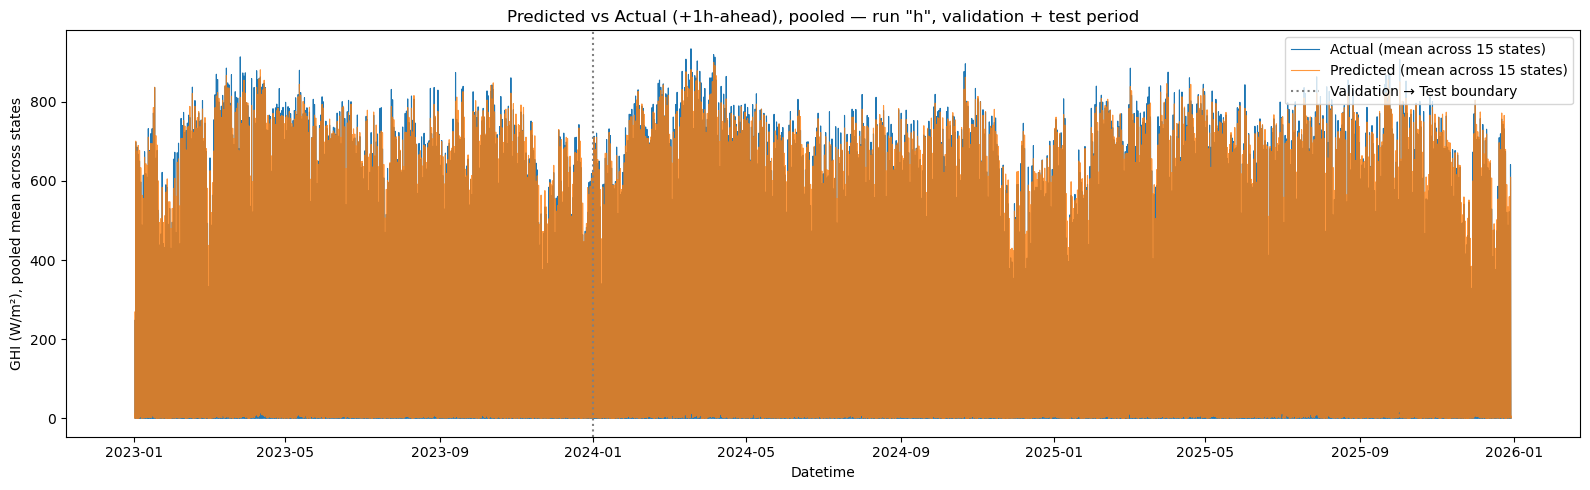

In [14]:
# Build the model's +1h-ahead prediction vs actual for every state,
# across the validation + test period (chronologically continuous),
# then average across all 15 states at each timestamp -- one pooled
# overview instead of 15 separate per-state subplots.

valtest_scaled = pd.concat([val_scaled, test_scaled]).sort_values(['State', 'Datetime'])
states = sorted(valtest_scaled["State"].unique())

per_state_series = []
for state in states:
    state_data = valtest_scaled[valtest_scaled['State'] == state].sort_values('Datetime')
    X_state = state_data[FEATURE_COLS].to_numpy(dtype='float32')
    actual_state = state_data[TARGET_COL].to_numpy(dtype='float32')
    dt_state = state_data['Datetime'].to_numpy()

    n = len(X_state)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue

    n_windows = n - WINDOW_SIZE - OUTPUT_HORIZON + 1
    Xw = sliding_window_view(X_state[: n - OUTPUT_HORIZON], WINDOW_SIZE, axis=0)[:n_windows]
    Xw = Xw.transpose(0, 2, 1).reshape(n_windows, -1)

    pred_scaled = model.predict(Xw)[:, 0]  # +1h-ahead column only
    pred = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    pred = np.clip(pred, 0, None)

    actual = actual_state[WINDOW_SIZE: WINDOW_SIZE + n_windows]
    dt_plot = dt_state[WINDOW_SIZE: WINDOW_SIZE + n_windows]

    per_state_series.append(pd.DataFrame({'Datetime': dt_plot, 'actual': actual, 'predicted': pred}))

pooled = pd.concat(per_state_series).groupby('Datetime', as_index=False).mean()
pooled = pooled.sort_values('Datetime')

plt.figure(figsize=(16, 5))
plt.plot(pooled['Datetime'], pooled['actual'], label='Actual (mean across 15 states)', linewidth=0.8)
plt.plot(pooled['Datetime'], pooled['predicted'], label='Predicted (mean across 15 states)', alpha=0.8, linewidth=0.8)
plt.axvline(test_df['Datetime'].min(), color='gray', linestyle=':', label='Validation → Test boundary')
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²), pooled mean across states')
plt.title(f'Predicted vs Actual (+1h-ahead), pooled — run "{RUN_NAME}", validation + test period')
plt.legend()
plt.tight_layout()
plt.show()


## 8a. Same plot, zoomed to one month (so the two lines are actually distinguishable)

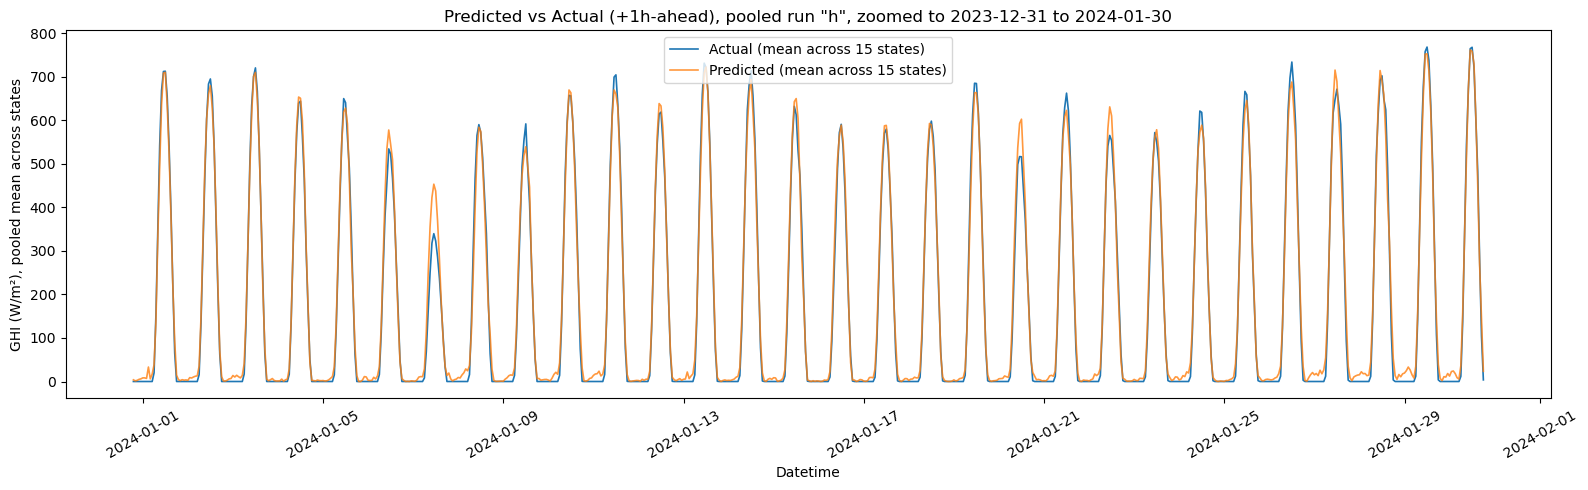

In [15]:
zoom_start = test_df["Datetime"].min()
zoom_end = zoom_start + pd.Timedelta(days=30)
zoomed = pooled[(pooled["Datetime"] >= zoom_start) & (pooled["Datetime"] < zoom_end)]

plt.figure(figsize=(16, 5))
plt.plot(zoomed["Datetime"], zoomed["actual"], label="Actual (mean across 15 states)", linewidth=1.2)
plt.plot(zoomed["Datetime"], zoomed["predicted"], label="Predicted (mean across 15 states)", alpha=0.8, linewidth=1.2)
plt.xlabel("Datetime")
plt.ylabel("GHI (W/m²), pooled mean across states")
plt.title(f"Predicted vs Actual (+1h-ahead), pooled run \"{RUN_NAME}\", zoomed to {zoom_start.date()} to {zoom_end.date()}")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 9. Save model & scalers

In [16]:
joblib.dump(model, f'linreg_{RUN_NAME}_model.joblib')
joblib.dump(x_scaler, f'linreg_{RUN_NAME}_x_scaler.joblib')
joblib.dump(y_scaler, f'linreg_{RUN_NAME}_y_scaler.joblib')
print(f'saved linreg_{RUN_NAME}_model.joblib + scalers.')

saved linreg_h_model.joblib + scalers.


## 10. Rolling-origin evaluation (real day D -> predict real day D+1)

In [17]:
# per-state raw (unscaled) arrays, test period only, using `df` (has correct
# lag features computed on the full un-split timeline)
TEST_START = test_df['Datetime'].min()

state_arrays = {}
for state, g in df.groupby('State', sort=False):
    g = g.sort_values('Datetime')
    g = g[g['Datetime'] >= TEST_START].reset_index(drop=True)
    state_arrays[state] = {
        'dt': g['Datetime'].to_numpy(),
        'X': g[FEATURE_COLS].to_numpy(dtype='float32'),
        'y': g[TARGET_COL].to_numpy(dtype='float32'),
    }

origin_windows, y_true_next_day, origin_meta = [], [], []

for state, arr in state_arrays.items():
    dt, X, y = arr['dt'], arr['X'], arr['y']
    n = len(dt)
    midnight_idx = np.where(pd.DatetimeIndex(dt).hour == 0)[0]  # candidate day-starts D
    for p in midnight_idx:
        if p + 2 * WINDOW_SIZE > n:
            continue  # need D's 24h + D+1's 24h both present
        origin_windows.append(X[p:p + WINDOW_SIZE])                        # D: real 24h window
        y_true_next_day.append(y[p + WINDOW_SIZE:p + 2 * WINDOW_SIZE])     # D+1: real GHI
        origin_meta.append((state, dt[p]))

origin_windows = np.stack(origin_windows)      # (n_origins, 24, n_features)
y_true_next_day = np.stack(y_true_next_day)    # (n_origins, 24)

print(f'{len(origin_meta)} origins across {len(state_arrays)} states')

10935 origins across 15 states


In [18]:
def scale_X_flat(batch):  # (n, 24, n_features) raw -> scaled, flattened (n, 24*n_features)
    flat = batch.reshape(-1, len(FEATURE_COLS))
    scaled = x_scaler.transform(flat).reshape(batch.shape)
    return scaled.reshape(batch.shape[0], -1).astype('float32')

# single forward pass -- no recursive loop needed, the whole day comes out at once
pred_scaled = model.predict(scale_X_flat(origin_windows))
y_pred_next_day = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)
y_pred_next_day = np.clip(y_pred_next_day, 0, None)

print('direct rollout done (single forward pass, no recursion):', y_pred_next_day.shape)

direct rollout done (single forward pass, no recursion): (10935, 24)


c:\Users\theke\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [19]:
y_true_flat = y_true_next_day.flatten()
y_pred_flat = y_pred_next_day.flatten()

rollout_mae = mean_absolute_error(y_true_flat, y_pred_flat)
rollout_rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
rollout_r2 = r2_score(y_true_flat, y_pred_flat)
rollout_mbe = np.mean(y_pred_flat - y_true_flat)
rollout_nrmse = (rollout_rmse / np.mean(y_true_flat)) * 100

print(f'Rolling-origin overall (all horizons pooled):')
print(f'  MAE:   {rollout_mae:.4f}')
print(f'  RMSE:  {rollout_rmse:.4f}')
print(f'  R2:    {rollout_r2:.4f}')
print(f'  MBE:   {rollout_mbe:.4f}')
print(f'  nRMSE: {rollout_nrmse:.2f}%')

horizon_rows = []
for h in range(WINDOW_SIZE):
    yt, yp = y_true_next_day[:, h], y_pred_next_day[:, h]
    horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
horizon_df = pd.DataFrame(horizon_rows)
horizon_df

Rolling-origin overall (all horizons pooled):
  MAE:   40.3408
  RMSE:  74.3257
  R2:    0.9266
  MBE:   3.3497
  nRMSE: 36.61%


,horizon_h,mae,rmse,r2
0,1,6.376493,12.847532,0.000000
1,2,8.113644,16.366586,0.000000
2,3,9.540489,18.927610,0.000000
3,4,11.171726,21.054013,0.000000
4,5,11.538313,21.243001,0.000000
5,6,14.201772,23.620697,-225.494949
6,7,21.971611,27.882505,-0.371548
7,8,36.928711,47.025986,0.356598
8,9,67.590973,86.449836,0.266000
9,10,87.389290,113.858332,0.216674


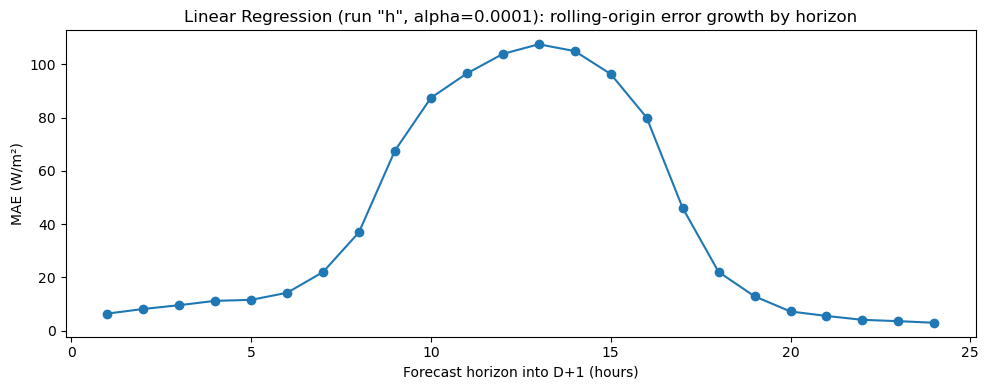

In [20]:
plt.figure(figsize=(10, 4))
plt.plot(horizon_df['horizon_h'], horizon_df['mae'], marker='o')
plt.xlabel('Forecast horizon into D+1 (hours)')
plt.ylabel('MAE (W/m²)')
plt.title(f'Linear Regression (run "{RUN_NAME}", alpha={ALPHA}): rolling-origin error growth by horizon')
plt.tight_layout(); plt.show()

In [21]:
# per-state breakdown, so the pooled number isn't hiding a bad state
state_of_origin = np.array([m[0] for m in origin_meta])
per_state_rows = []
for state in sorted(set(state_of_origin)):
    mask = state_of_origin == state
    yt = y_true_next_day[mask].flatten()
    yp = y_pred_next_day[mask].flatten()
    per_state_rows.append({
        'state': state, 'n_origins': int(mask.sum()),
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
per_state_df = pd.DataFrame(per_state_rows)
per_state_df

,state,n_origins,mae,rmse,r2
0,Johor (Johor Bahru),729,45.744488,87.764555,0.886663
1,Kedah (Alor Setar),729,39.316589,70.951929,0.934248
2,Kelantan (Kota Bharu),729,45.585152,83.291134,0.916778
3,Kuala Lumpur,729,34.980721,65.256065,0.938623
4,Melaka (Bandar Melaka),729,38.831963,69.706979,0.930061
5,Negeri Sembilan (Seremban),729,41.125477,75.816986,0.926237
6,Pahang (Kuantan),729,42.797371,80.495208,0.915978
7,Penang (George Town),729,38.606174,71.333353,0.936905
8,Perak (Ipoh),729,34.418350,62.031502,0.946722
9,Perlis (Kangar),729,40.248535,70.990234,0.934177


## 10b. Actual vs. predicted, one concrete forecast example

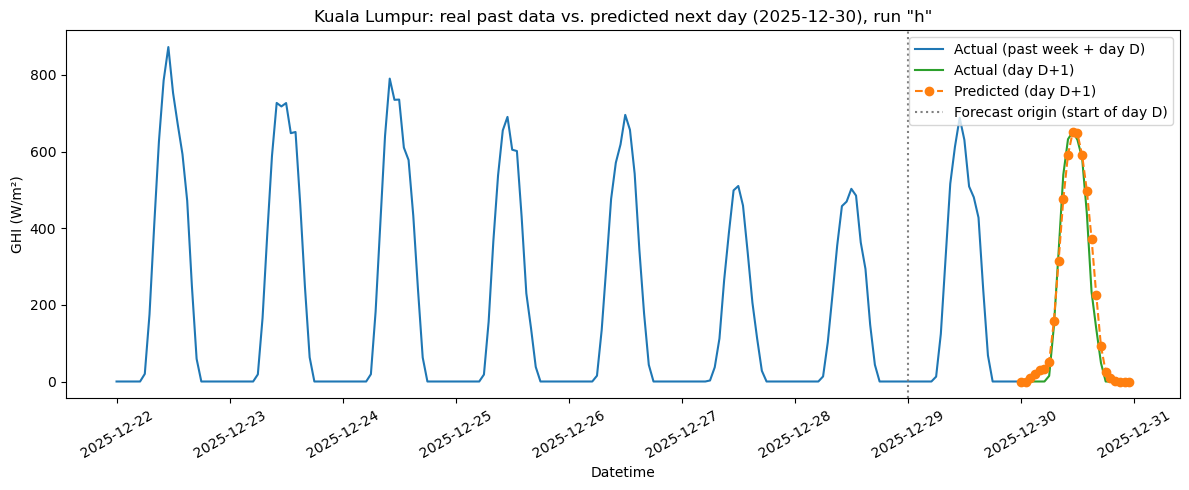

In [22]:
EXAMPLE_STATE = 'Kuala Lumpur'
N_PAST_DAYS = 7

example_indices = [i for i, m in enumerate(origin_meta) if m[0] == EXAMPLE_STATE]
example_idx = example_indices[-1]

arr = state_arrays[EXAMPLE_STATE]
origin_dt = origin_meta[example_idx][1]
origin_pos = np.where(arr['dt'] == origin_dt)[0][0]

past_start = max(0, origin_pos - N_PAST_DAYS * WINDOW_SIZE)
past_dt = arr['dt'][past_start:origin_pos + WINDOW_SIZE]
past_actual = arr['y'][past_start:origin_pos + WINDOW_SIZE]

next_day_dt = arr['dt'][origin_pos + WINDOW_SIZE:origin_pos + 2 * WINDOW_SIZE]
next_day_actual = y_true_next_day[example_idx]
next_day_pred = y_pred_next_day[example_idx]

plt.figure(figsize=(12, 5))
plt.plot(past_dt, past_actual, color='tab:blue', label='Actual (past week + day D)')
plt.plot(next_day_dt, next_day_actual, color='tab:green', label='Actual (day D+1)')
plt.plot(next_day_dt, next_day_pred, color='tab:orange', linestyle='--', marker='o', label='Predicted (day D+1)')
plt.axvline(arr['dt'][origin_pos], color='gray', linestyle=':', label='Forecast origin (start of day D)')
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²)')
plt.title(f'{EXAMPLE_STATE}: real past data vs. predicted next day ({pd.Timestamp(next_day_dt[0]).date()}), run "{RUN_NAME}"')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [23]:
horizon_df.to_csv(f'rolling_origin_direct_by_horizon_{RUN_NAME}.csv', index=False)
per_state_df.to_csv(f'rolling_origin_direct_by_state_{RUN_NAME}.csv', index=False)
print(f'saved rolling_origin_direct_by_horizon_{RUN_NAME}.csv, rolling_origin_direct_by_state_{RUN_NAME}.csv')

saved rolling_origin_direct_by_horizon_h.csv, rolling_origin_direct_by_state_h.csv


## 11. Save run summary (for cross-run comparison)

In [24]:
summary = {
    'run_name': RUN_NAME,
    'alpha': ALPHA,
    # the metric to use for picking the sweep winner (RMSE primary, MAE/R2 supporting) --
    # test_pooled/rollout_pooled below are recorded for completeness only, not for selection
    'validation_pooled': {
        'mae': float(val_mae), 'rmse': float(val_rmse), 'r2': float(val_r2),
        'mbe': float(val_mbe), 'nrmse': float(val_nrmse),
    },
    'train_duration_sec': train_duration_sec,
    'test_pooled': {
        'mae': float(mae), 'rmse': float(rmse), 'r2': float(r2),
        'mbe': float(test_mbe), 'nrmse': float(test_nrmse),
    },
    'test_persistence_baseline': {'mae': float(baseline_mae), 'rmse': float(baseline_rmse)},
    'rollout_pooled': {
        'mae': float(rollout_mae), 'rmse': float(rollout_rmse), 'r2': float(rollout_r2),
        'mbe': float(rollout_mbe), 'nrmse': float(rollout_nrmse),
    },
}

with open(f'summary_{RUN_NAME}.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "run_name": "h",
  "alpha": 0.0001,
  "validation_pooled": {
    "mae": 38.334224700927734,
    "rmse": 70.98520903923401,
    "r2": 0.93287193775177,
    "mbe": 3.221510887145996,
    "nrmse": 35.037624899954004
  },
  "train_duration_sec": 13.511850595474243,
  "test_pooled": {
    "mae": 38.87335968017578,
    "rmse": 72.07986428911683,
    "r2": 0.9309927821159363,
    "mbe": 2.730081558227539,
    "nrmse": 35.49892508129441
  },
  "test_persistence_baseline": {
    "mae": 43.7045747161511,
    "rmse": 94.16477080474115
  },
  "rollout_pooled": {
    "mae": 40.340755462646484,
    "rmse": 74.32569597407918,
    "r2": 0.9266186952590942,
    "mbe": 3.34971284866333,
    "nrmse": 36.60650848683467
  }
}
